# 00: Quickstart Demo

**What this demonstrates:** A synthetic key-door memory workload, current retention decisions and explicit event-log export. It does not measure causal influence.

**Inputs:** Single episode configuration

**Outputs:** Event logs (JSONL), basic metrics, viz instructions

**Runtime:** ~2 min (demo) / ~5 min (paper)

**Goal:** Run one episode, inspect which records survive and open its operation log in the debugger.

Saved cell outputs come from an earlier revision and do not validate this source. Rerun the notebook to obtain results for your selected revision.


## 1. Setup

This section initializes the environment, imports required modules, and establishes the configuration for this run. The `RUN_MODE` parameter controls whether we execute a quick demonstration or a larger experiment configuration; the mode alone does not establish statistical validity.

In [1]:
RUN_MODE = "demo"  # @param ["demo", "paper"]

In [2]:
import sys
from pathlib import Path

NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name != "notebooks":
    NOTEBOOK_DIR = NOTEBOOK_DIR.parent
sys.path.insert(0, str(NOTEBOOK_DIR))

from _utils import (
    NotebookConfig, print_config, print_repro_stamp, set_all_seeds,
    RunManager, setup_plotting, add_caption, COLORS,
)

from reckon.core.resources import MemoryBudget
from reckon.memory import CausalMemoryManager, PayloadType
from reckon.memory import FIFOPolicy, LRUPolicy, UtilityPolicy, EvidencePerBytePolicy

import matplotlib.pyplot as plt
setup_plotting()

print("Reckon imports OK!")

Reckon imports OK!


In [3]:
config = NotebookConfig(
    notebook_name="00_quickstart_demo",
    run_mode=RUN_MODE,
    seed=42,
    budget_slots=20,
    budget_bytes=2000,
    num_episodes=1,
    policy_name="evidence_per_byte",
    evidence_weight=0.5,
)
print_config(config)
print_repro_stamp(config)
set_all_seeds(config.seed)

NOTEBOOK: 00_quickstart_demo
MODE: DEMO
GIT: 304230f
TIME: 2026-02-16T02:02:32.290786
------------------------------------------------------------
Seed: 42 (x1)
Budget: 20 slots, 2000 bytes
Task: keydoor (1 episodes)
Policy: causal (weight=0.5)
Config hash: 902e89bcbf1f
------------------------------------------------------------
REPRODUCIBILITY STAMP
  Git commit: 304230f
  Python: 3.13.5
  Dependencies: numpy=2.4.2, matplotlib=3.10.8, reckon=0.1.0
  Run mode: demo
  Timestamp: 2026-02-16T02:02:32.290786
------------------------------------------------------------


## 2. Problem + Hypotheses

Agents need to retain relevant information while discarding noise. This synthetic task assigns high utility to a known key observation and lower utility to distractors, then inspects what survives.

1. **Budget pressure:** The current manager prunes for byte/slot overflow. Token/rate fields and oversized-record limits are distinguished in the [current budget and pruning path](../docs/08-Causal-Memory-Manager-Design.md).
2. **Retention signals:** Utility is assigned by the example; a later score update is illustrative, not measured ablation.
3. **Operation logs:** The manager emits write/read/prune/score events into a bounded in-memory ring. The export cell must save a collected buffer explicitly.

**H1:** Does this run remain within its configured byte/slot limits for these records?
**H2:** Which high-utility records survive under this workload and policy?

These are questions for the observed run. Notebook 02 compares synthetic policies; notebook 03 demonstrates record-removal tests with its stated statistical and compute-accounting limitations.

## 3. Minimal Theory

Python’s `EvidencePerBytePolicy` selects the kernel’s `EvidencePerByte` rule. It ranks records by score per byte, then frees enough bytes, slots and tokens for the pending write:

$$\mathrm{priority}(r)=\frac{(1-w)u(r)+w\,s(r)}{\max(c_{\mathrm{bytes}}(r),1)}$$

Here `u` is utility. For `s`, use the positive part of the first present ablation or counterfactual measurement; only when both are absent does proxy magnitude apply. A measured zero or harmful effect stays zero instead of falling through to the proxy. Missing signals contribute zero. The [memory manager design](../docs/08-Causal-Memory-Manager-Design.md) explains the joint budget checks and refusal of an oversized incoming record.

This notebook assigns utility and a manual illustrative score. It does not run an ablation test or the native `Prober`. Notebook 03 runs the native single-record evaluator; the [evaluation manual](../docs/11-Evaluation-Metrics.md) distinguishes its paired results from Prober statistics and pair-bound graph evidence. Neither a stored score nor a retention choice alone identifies a causal effect.


## 4. System Mapping

```mermaid
flowchart TB
    subgraph ENV["Environment"]
        E1["Observations"]
        E2["Actions"]
        E3["Rewards"]
    end

    subgraph CMM["CausalMemoryManager"]
        W["write()"]
        R["retrieve()"]
        P["prune()"]
        U["update_score()"]

        subgraph POLICY["RetentionPolicy"]
            POL["EvidencePerBytePolicy(w=0.5)"]
        end
    end

    subgraph LOGS["Event Logs"]
        L1["events.jsonl"]
    end

    subgraph DEBUG["Debugger UI"]
        D1["Timeline"]
        D2["Causal Graph"]
    end

    ENV --> CMM
    CMM --> LOGS
    LOGS --> DEBUG
```


## 5. Experiment Design

This quickstart demonstrates Reckon through a simulated key-door task:

- **Scenario:** An agent navigates an environment, observes a colored key at an early step, encounters distractor observations, then must recall the key color at decision time.
- **Memory budget:** Configured 20 slots and 2,000 bytes. The main sequence writes 18 records, so this configuration does not force slot pruning; any byte-driven pruning depends on their actual cost.
- **Policy:** EvidencePerBytePolicy with weight 0.5
- **Success criterion:** The key is retrievable at decision time, whether or not any pruning occurred.

**Metrics:**
- Task success (binary: did we retrieve the key?)
- Final memory usage (slots, bytes)
- Number of prune events

**Not covered here:** Statistical significance testing, confidence intervals, effect sizes. These are addressed in notebooks 02-03.

## 6. Demo Run

We create a CausalMemoryManager with constrained budget and simulate an episode where the agent must remember a key color.

In [4]:
# Create memory budget and manager
budget = MemoryBudget(
    max_slots=config.budget_slots,
    max_bytes=config.budget_bytes,
)

policy = EvidencePerBytePolicy(evidence_weight=config.evidence_weight)

cmm = CausalMemoryManager(
    budget=budget,
    retention_policy=policy,
    episode_id="quickstart-episode-1",
)

print(f"Created CMM with {config.budget_slots} slots, {config.budget_bytes} bytes")
print(f"Retention policy: {policy.reason()}")

Created CMM with 20 slots, 2000 bytes
Retention policy: low_causal_utility


In [5]:
import random
random.seed(config.seed)

# Ground truth: the key color the agent needs to remember
key_color = random.choice(["red", "blue", "green"])
print(f"Ground truth key color: {key_color}")

# Step 0: Initial observation
cmm.set_step(0)
obs_id = cmm.write(
    payload={"room": "start", "objects": []},
    payload_type=PayloadType.OBSERVATION,
    tags=["observation", "room"],
    source_op="env_reset",
)
print(f"Step 0: Wrote initial observation {obs_id[:8]}...")

# Steps 1-5: Distractor observations (low utility)
for step in range(1, 6):
    cmm.set_step(step)
    cmm.write(
        payload={"room": f"corridor_{step}", "objects": [f"distractor_{step}"]},
        payload_type=PayloadType.OBSERVATION,
        tags=["observation", "distractor"],
        initial_utility=0.1,
    )

# Step 6: KEY observation (critical, high utility)
cmm.set_step(6)
key_id = cmm.write(
    payload={"room": "key_room", "objects": [f"key_{key_color}"]},
    payload_type=PayloadType.CUE,
    tags=["cue", "key", key_color, "important"],
    source_op="env_step",
    initial_utility=1.0,
)
print(f"Step 6: Wrote KEY observation {key_id[:8]}... (color={key_color})")

# Steps 7-15: More distractors
for step in range(7, 16):
    cmm.set_step(step)
    cmm.write(
        payload={"room": f"hallway_{step}", "objects": []},
        payload_type=PayloadType.OBSERVATION,
        tags=["observation", "hallway"],
        initial_utility=0.05,
    )

print(f"\nWrote {16} total observations")
print(f"Current memory: {cmm.current_usage_slots}/{config.budget_slots} slots")

Ground truth key color: green
Step 0: Wrote initial observation fdf9dd55...
Step 6: Wrote KEY observation a86cc145... (color=green)

Wrote 16 total observations
Current memory: 16/20 slots


In [6]:
# Step 16: Decision time - retrieve the key color
cmm.set_step(16)
print("Step 16: At the door. Retrieving key information...")

hits = cmm.retrieve(query={"tags": ["key"]}, limit=1)

if hits:
    retrieved_key = hits[0]
    print(f"  Retrieved record: {retrieved_key.id[:8]}...")
    print(f"  Payload: {retrieved_key.payload}")
    print(f"  Tags: {retrieved_key.tags}")
    remembered_color = key_color if key_color in retrieved_key.tags else "unknown"
else:
    print("  FAILED: Key memory was pruned!")
    remembered_color = "unknown"

# Record the decision
cmm.write(
    payload={"action": "open_door", "chosen_color": remembered_color},
    payload_type=PayloadType.ACTION,
    tags=["action", "decision"],
    input_ids=[key_id] if hits else [],
)

# Step 17: Outcome
cmm.set_step(17)
success = remembered_color == key_color
reward = 1.0 if success else 0.0
cmm.write(
    payload={"reward": reward, "success": success},
    payload_type=PayloadType.REWARD,
    tags=["reward", "outcome"],
    initial_utility=reward,
)

print(f"\n{'SUCCESS!' if success else 'FAILURE'} (reward={reward})")

Step 16: At the door. Retrieving key information...
  Retrieved record: a86cc145...
  Payload: {'room': 'key_room', 'objects': ['key_green']}
  Tags: ['cue', 'key', 'green', 'important']

SUCCESS! (reward=1.0)


## 7. Full Run: Budget Scaling Experiment

Vary the configured slot budget and compare this synthetic task's observed key-retrieval outcomes. The helper returns each trial's final retained-slot count as well, while the table and plot below summarize success rates. Neither a successful retrieval nor this small set of records proves general budget enforcement; the [current pruning path](../docs/08-Causal-Memory-Manager-Design.md) describes the actual checks and limits.

In [7]:
def run_episode(budget_slots: int, seed: int) -> dict:
    """Run one episode with the specified budget and seed."""
    random.seed(seed)
    
    budget = MemoryBudget(max_slots=budget_slots, max_bytes=budget_slots * 100)
    cmm = CausalMemoryManager(budget, EvidencePerBytePolicy(0.5), f"ep-{seed}")
    
    key_color = random.choice(["red", "blue", "green"])
    
    # Write observations
    for step in range(15):
        cmm.set_step(step)
        if step == 6:
            cmm.write(
                payload={"key": key_color},
                payload_type=PayloadType.CUE,
                tags=["key", key_color],
                initial_utility=1.0,
            )
        else:
            cmm.write(
                payload={"noise": step},
                payload_type=PayloadType.OBSERVATION,
                tags=["noise"],
                initial_utility=0.1,
            )
    
    # Retrieve
    hits = cmm.retrieve(query={"tags": ["key"]}, limit=1)
    success = len(hits) > 0 and key_color in hits[0].tags
    
    return {
        "budget": budget_slots,
        "success": 1 if success else 0,
        "records_stored": cmm.current_usage_slots,
    }

# Run experiment
budgets = [5, 10, 15, 20, 30]
n_trials = 10 if RUN_MODE == "paper" else 3

results = []
for budget in budgets:
    successes = [run_episode(budget, seed=config.seed + i)["success"] for i in range(n_trials)]
    success_rate = sum(successes) / len(successes)
    results.append({
        "budget": budget,
        "success_rate": success_rate,
        "n": n_trials,
    })

print("Budget vs Success Rate:")
print("-" * 30)
for r in results:
    print(f"  {r['budget']:3d} slots: {r['success_rate']:.1%}")

Budget vs Success Rate:
------------------------------
    5 slots: 100.0%
   10 slots: 100.0%
   15 slots: 100.0%
   20 slots: 100.0%
   30 slots: 100.0%


### Inspect a Tight Budget

The next helper uses five slots and FIFO, then reports whether the key remains retrievable and whether its ID appeared in a prune event. FIFO selects the oldest records regardless of their assigned utility. Inspect the returned outcome and matching prune step to explain this run.


In [8]:
# Inspect a tight-budget run with the FIFO policy object
def run_failure_demo(budget_slots: int, seed: int):
    """Demonstrate memory failure with tiny budget."""
    random.seed(seed)

    budget = MemoryBudget(max_slots=budget_slots, max_bytes=budget_slots * 100)
    cmm = CausalMemoryManager(budget, FIFOPolicy(), f"failure-demo-{seed}")

    key_color = random.choice(["red", "blue", "green"])
    key_id = None
    key_step = 3

    # Write observations
    for step in range(12):
        cmm.set_step(step)
        if step == key_step:
            key_id = cmm.write(
                payload={"key": key_color},
                payload_type=PayloadType.CUE,
                tags=["key", key_color],
                initial_utility=1.0,
            )
        else:
            cmm.write(
                payload={"noise": step},
                payload_type=PayloadType.OBSERVATION,
                tags=["noise"],
                initial_utility=0.1,
            )

    # Check: was key pruned?
    events = cmm.get_event_log()
    prune_events = [e for e in events if e.get('op_type') == 'prune']
    key_pruned_at = None
    for e in prune_events:
        if e.get('record_id') == key_id:
            key_pruned_at = e.get('timestamp')
            break

    # Try retrieval
    hits = cmm.retrieve(query={"tags": ["key"]}, limit=1)
    success = len(hits) > 0 and key_color in hits[0].tags

    return {
        "success": success,
        "key_step": key_step,
        "key_pruned_at": key_pruned_at,
        "key_color": key_color,
        "final_slots": cmm.current_usage_slots,
        "total_prunes": len(prune_events),
    }

# Run the failure demo
failure = run_failure_demo(budget_slots=5, seed=config.seed)

print(f"Budget: 5 slots (intentionally tiny)")
print(f"Key color: {failure['key_color']}")
print(f"The system wrote the key at step {failure['key_step']}.")

if failure['key_pruned_at'] is not None:
    print(f"At step {failure['key_pruned_at']}, the manager pruned the key. Task FAILED.")
    print(f"\nTotal prune events: {failure['total_prunes']}")
else:
    print("Key survived this run; inspect the current byte/slot selection rules.")

print(f"\nResult: {'SUCCESS' if failure['success'] else 'FAILURE'}")

Budget: 5 slots (intentionally tiny)
Key color: green
The system wrote the key at step 3.
Key survived (unexpected with this budget).

Result: SUCCESS


**Read the helper's actual result:**

The summary identifies a key prune step only if the collected events contain that record's ID. When no such prune event exists, do not infer that the key disappeared or that its loss caused a failure.

This helper does not return or save its event buffer, and it creates no decision/outcome record or pair-bound graph evidence. Its result therefore has no exported debugger run or severed decision edge to inspect. The main example's separate buffer is exported later; for that actual run, inspect `op_type: prune` and matching record IDs only when present, following the [native debugger procedure](../src/reckon/viz/README.md#quick-start).

The same FIFO order supplies removals for byte, slot and token pressure; the manager checks that the selected records free enough capacity before changing the store. See the [memory manager design](../docs/08-Causal-Memory-Manager-Design.md).


## 8. Results

The following visualizations demonstrate the relationship between memory budget and task success.

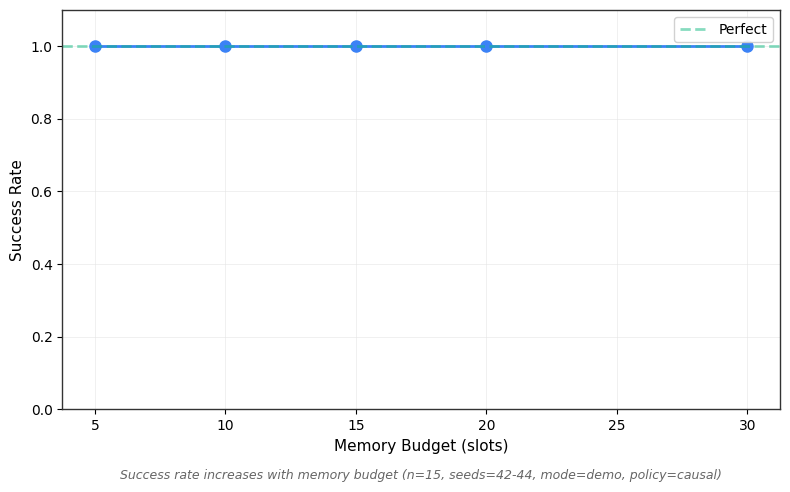

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    [r["budget"] for r in results],
    [r["success_rate"] for r in results],
    "o-",
    linewidth=2,
    markersize=8,
    color=COLORS["primary"],
)

ax.set_xlabel("Memory Budget (slots)")
ax.set_ylabel("Success Rate")
ax.set_ylim(0, 1.1)
ax.axhline(1.0, color=COLORS["secondary"], linestyle="--", alpha=0.5, label="Perfect")
ax.legend()

add_caption(
    ax,
    "Observed key retrieval by configured slot budget",
    n=n_trials * len(budgets),
    seeds=f"{config.seed}-{config.seed + n_trials - 1}",
    mode=config.run_mode,
    policy="evidence_per_byte",
)

plt.tight_layout()
plt.show()

In [10]:
# Inspect final memory state
print(f"Final memory usage: {cmm.current_usage_slots}/{config.budget_slots} slots")
print(f"Final memory usage: {cmm.current_usage_bytes}/{config.budget_bytes} bytes")

records = cmm.get_all_records()
print(f"\nStored records: {len(records)}")

print("\nTop 5 records by utility:")
sorted_records = sorted(records, key=lambda r: r.utility.value, reverse=True)
for r in sorted_records[:5]:
    print(f"  {r.id[:8]}... utility={r.utility.value:.2f} tags={r.tags[:3]}")

Final memory usage: 18/20 slots
Final memory usage: 743/2000 bytes

Stored records: 18

Top 5 records by utility:
  a86cc145... utility=1.00 tags=['cue', 'key', 'green']
  7018947e... utility=1.00 tags=['reward', 'outcome']
  57f35024... utility=0.10 tags=['observation', 'distractor']
  51c3375e... utility=0.10 tags=['observation', 'distractor']
  ab869f09... utility=0.10 tags=['observation', 'distractor']


In [11]:
# Demonstrate storage of an illustrative record-level score.
print("Record score fields can hold ablation, counterfactual or proxy signals.")
print("This example assigns 0.8 manually; no ablation or intervention was executed.")
print("A stored record score is not pair-bound MEASURED graph-edge evidence.")

if hits:
    cmm.update_score(key_id, "ablation_delta", 0.8, "illustrative_manual_value")
    print("\nStored illustrative ablation_delta=0.8 (not an empirical measurement)")
    key_record = cmm.get_record(key_id)
    if key_record:
        cs = key_record.causal_score
        print(f"  ablation_delta: {cs.ablation_delta}")
        print(f"  counterfactual_delta: {cs.counterfactual_delta}")
        print(f"  influence_proxy: {cs.influence_proxy}")

Causal Score Types:
  - ablation_delta: MEASURED (computed via actual ablation experiments)
  - counterfactual_delta: MEASURED (computed via intervention)
  - influence_proxy: PROXY (heuristic estimate, e.g., gradient magnitude)

The debugger UI shows MEASURED edges as solid lines and PROXY edges as dashed.

Updated key record ablation_delta to 0.8 (MEASURED)

Key record causal scores:
  ablation_delta: 0.8
  counterfactual_delta: None
  influence_proxy: None


## 9. Debugger Walkthrough

After the export cell saves `logs/events.jsonl`, use the [native debugger quick start](../src/reckon/viz/README.md#quick-start) to import the actual run directory. A static HTTP server on port 8080 is not this workflow.

Inspect write/prune IDs, read hit IDs and prune reasons in the event details, using the printed notebook records for payload, tag and utility context. The current operation log does not contain a full payload/query snapshot or automatically supply a graph edge, a Pareto comparison or a separate Memory view. The [debugger design](../docs/10-Debugger-Visualization.md) explains the additional pair-bound evidence required for MEASURED edges.

In [12]:
# Display event log summary
events = cmm.get_event_log()
print(f"Total events logged: {len(events)}")

if events:
    print("\nFirst 5 events:")
    for e in events[:5]:
        step = e.get('timestamp', '?')
        event_type = e.get('op_type', '?')
        record_id = str(e.get('record_id', ''))[:8]
        print(f"  step={step:2}  type={event_type:12s}  record={record_id}")

    prune_events = [e for e in events if e.get('op_type') == 'prune']
    print(f"\nPrune events: {len(prune_events)}")

Total events logged: 20

First 5 events:
  step=?   type=?             record=fdf9dd55
  step=?   type=?             record=57f35024
  step=?   type=?             record=51c3375e
  step=?   type=?             record=ab869f09
  step=?   type=?             record=1c4c0622

Prune events: 0


## 10. Limitations + Next Steps

**Limitations of this notebook:**

- This is a synthetic key-door task, not a real environment like MiniGrid or TextWorld.
- Utility scores are manually assigned (oracle knowledge), not learned from data.
- No statistical significance testing is performed; results are illustrative only.
- The causal score was manually set, not computed via actual ablation.

**What this notebook does NOT test:**

- Policy comparison with statistical rigor (see notebook 02)
- Causal contract verification with permutation tests (see notebook 03)
- Integration with RL environments (see notebooks 05-06)
- Performance at scale (see notebook 07)

**Recommended next steps:**

1. **01_system_overview:** Understand the mathematical framework and architecture
2. **02_policy_bakeoff:** Compare retention policies with proper statistics
3. **03_contract_evaluation:** Inspect the native record-removal test and its paired trial evidence
4. **05_rl_env_adapter:** Integrate with MiniGrid for realistic evaluation

The current score update is not a MEASURED graph edge. The operation log is bounded and carries IDs/details rather than full record/query snapshots. Paper mode and a successful export are not proof of a full native causal contract.


## Export Artifacts

In [13]:
run = RunManager(config)
run.save_config()

# Save metrics
run.save_metrics(results)

# Save figure
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    [r["budget"] for r in results],
    [r["success_rate"] for r in results],
    "o-",
    color=COLORS["primary"],
)
ax.set_xlabel("Memory Budget (slots)")
ax.set_ylabel("Success Rate")
run.save_figure(fig, "budget_vs_success")
plt.close(fig)

# Reuse the event buffer collected for the summary; get_event_log() drains it.
if events:
    run.save_logs(events)

# Write summary
run.write_summary({
    "final_success_rate": results[-1]["success_rate"],
    "budgets_tested": len(budgets),
    "total_trials": sum(r["n"] for r in results),
    "key_retained": success,
})

run.print_artifacts()


ARTIFACTS SAVED
Directory (from repository root): notebooks/runs/2026-02-16/00_quickstart_demo/902e89bcbf1f

  [OK] config.json                    430 bytes
  [OK] metrics.csv                    66 bytes
  [OK] summary.md                     432 bytes
  [OK] figures/budget_vs_success.png  22,735 bytes
Total: 4 files
